In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/meherunnesanithi/wholesale-customer/Wholesale customers data.csv


## Clustering on the Wholesale Customers Dataset

This notebook applies the same clustering techniques (K-means, Hierarchical, DBSCAN, Spectral) to the **Wholesale customers** dataset. The dataset has 440 customers of a wholesale distributor, with their annual spending (in monetary units) on 6 product categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicassen. `Channel` (Horeca / Retail) and `Region` are categorical, so we leave them out of the clustering and use them later to check our results.

In [2]:
import glob
path = glob.glob('/kaggle/input/datasets/meherunnesanithi/wholesale-customer/*.csv')[0]
print(path)

/kaggle/input/datasets/meherunnesanithi/wholesale-customer/Wholesale customers data.csv


## Cell 1 : File path

In [3]:
path='/kaggle/input/datasets/meherunnesanithi/wholesale-customer/Wholesale customers data.csv'

## Cell 2 : File load

In [4]:
import pandas as pd
customers = pd.read_csv(path,header='infer')
customers.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


##  Cell 3 :Data preparation

In [5]:
import numpy as np
from sklearn.preprocessing import StandardScaler

spend_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
scaler = StandardScaler().fit(np.log1p(customers[spend_cols]))
data = pd.DataFrame(scaler.transform(np.log1p(customers[spend_cols])), columns=spend_cols)
data.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


## Cell 4 : Indenify the Cluster Id using K-means

In [6]:
from sklearn import cluster

k_means = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means.fit(data)
labels = k_means.labels_
pd.DataFrame(labels, index=customers.index, columns=['Cluster ID']).head()

,Cluster ID
0,0
1,0
2,0
3,1
4,0


## Cell 5:  Showing both cluster centroid

In [7]:
centroids = k_means.cluster_centers_
pd.DataFrame(centroids,columns=data.columns)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,-0.296165,0.809123,0.859967,-0.345123,0.885101,0.200763
1,0.220948,-0.603632,-0.641562,0.257473,-0.660314,-0.149776


## Cell 6: Matching cluster with real channel 

In [8]:
pd.crosstab(customers['Channel'], labels, rownames=['Channel'], colnames=['Cluster ID'])

Cluster ID,0,1
Channel,,
1,54,244
2,134,8


## Cell 7 : Assign  new 5 customer in cluster 

In [9]:
testData = np.array([[20000,2000,3000,5000,300,1000],[3000,9000,14000,500,6000,1200],[9000,5000,6000,2000,1500,1500],[15000,1500,2000,8000,200,700],[2000,7000,12000,300,5000,900]])
testDF = pd.DataFrame(testData, columns=spend_cols)
scaledTest = pd.DataFrame(scaler.transform(np.log1p(testDF)), columns=spend_cols)
labels = k_means.predict(scaledTest)
labels = labels.reshape(-1,1)
usernames = np.array(['cust_A','cust_B','cust_C','cust_D','cust_E']).reshape(-1,1)
cols = spend_cols.copy()
cols.insert(0,'customer')
cols.append('Cluster ID')
newcustomers = pd.DataFrame(np.concatenate((usernames, testData, labels), axis=1),columns=cols)
newcustomers

,customer,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster ID
0,cust_A,20000,2000,3000,5000,300,1000,1
1,cust_B,3000,9000,14000,500,6000,1200,0
2,cust_C,9000,5000,6000,2000,1500,1500,0
3,cust_D,15000,1500,2000,8000,200,700,1
4,cust_E,2000,7000,12000,300,5000,900,0


## Cell 8 : Elbow plot

Text(0, 0.5, 'SSE')

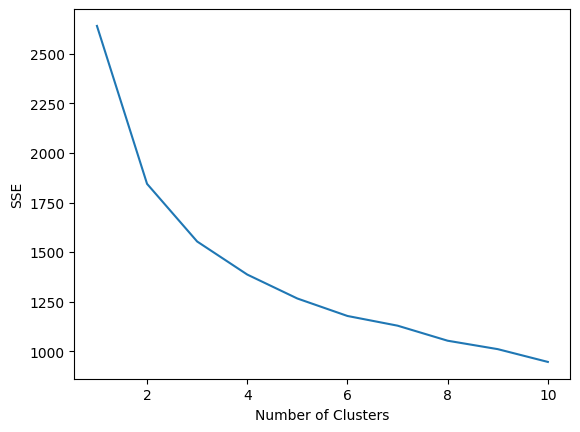

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

numClusters = [1,2,3,4,5,6,7,8,9,10]
SSE = []
for k in numClusters:
    k_means = cluster.KMeans(n_clusters=k, random_state=1)
    k_means.fit(data)
    SSE.append(k_means.inertia_)

plt.plot(numClusters, SSE)
plt.xlabel('Number of Clusters')
plt.ylabel('SSE')

## Cell 9 : Single link dendrogram

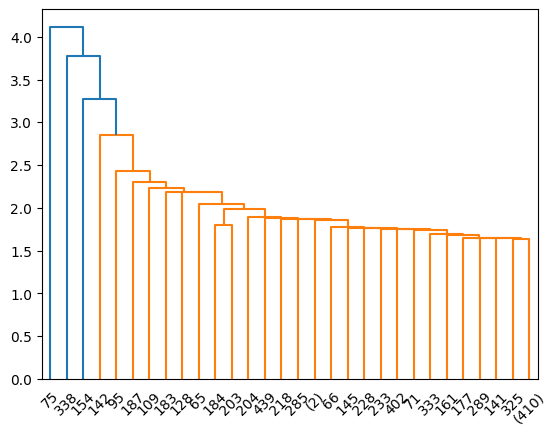

In [11]:
from scipy.cluster import hierarchy
import matplotlib.pyplot as plt
%matplotlib inline

X = data
Z = hierarchy.linkage(X.values, 'single')
dn = hierarchy.dendrogram(Z, truncate_mode='lastp', p=30)

## Cell 10 : Complete link dendrogram

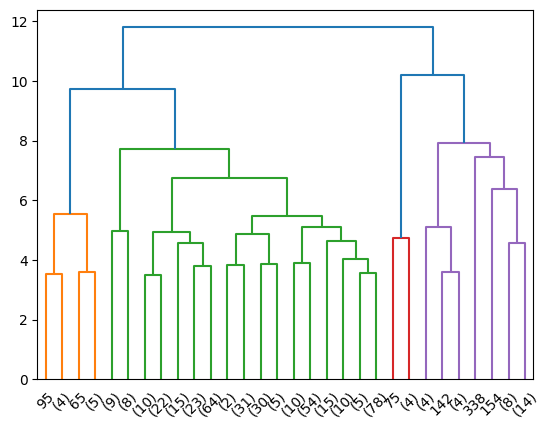

In [12]:
Z = hierarchy.linkage(X.values, 'complete')
dn = hierarchy.dendrogram(Z, truncate_mode='lastp', p=30)

## Cell 11 : Group average dendrogram

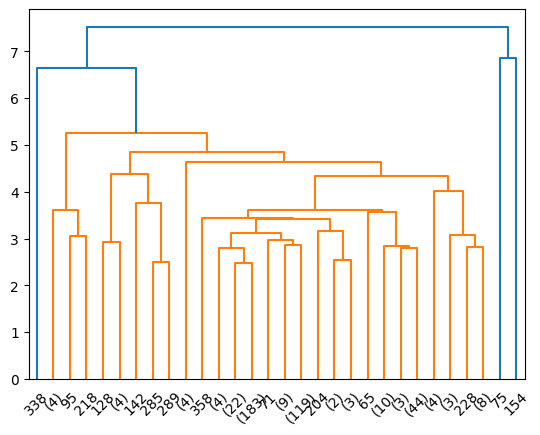

In [13]:
Z = hierarchy.linkage(X.values, 'average')
dn = hierarchy.dendrogram(Z, truncate_mode='lastp', p=30)

## Cell 12 : Reduced the data to 2D using PCA and visualized it with a scatter plot.

<Axes: xlabel='x', ylabel='y'>

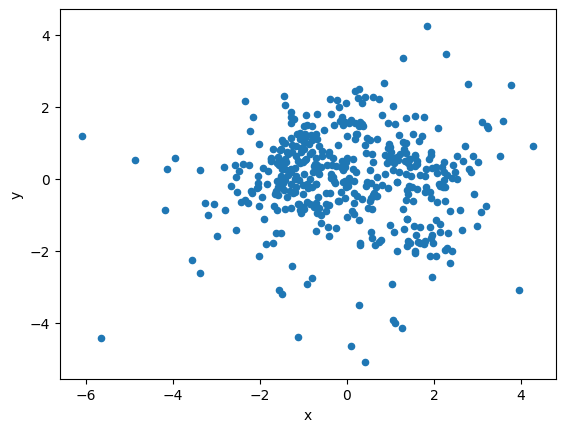

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=1)
points = pd.DataFrame(pca.fit_transform(data), columns=['x','y'])
points.plot.scatter(x='x',y='y')

## Cell 13 : Applied DBSCAN clustering and visualized the clusters using a scatter plot, with noise points labeled as -1

<Axes: xlabel='x', ylabel='y'>

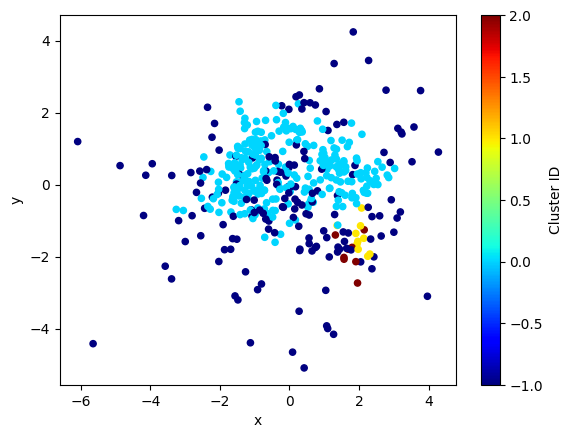

In [15]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.9, min_samples=5).fit(data)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = pd.DataFrame(db.labels_,columns=['Cluster ID'])
result = pd.concat((points,labels), axis=1)
result.plot.scatter(x='x',y='y',c='Cluster ID', colormap='jet')

## Cell 14 :Applied K-Means clustering (k=2) to the 2D PCA-transformed data and visualized the clusters using a scatter plot.

Text(0.5, 1.0, 'K-means Clustering')

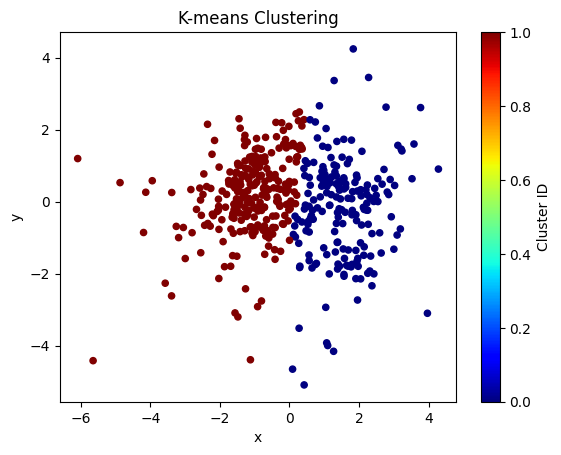

In [16]:
from sklearn import cluster

k_means = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means.fit(points)
labels1 = pd.DataFrame(k_means.labels_,columns=['Cluster ID'])
result1 = pd.concat((points,labels1), axis=1)

result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet')
plt.title('K-means Clustering')

## Cell 15 : Ran Spectral Clustering and compared it side-by-side with K-Means, then matched both clusters with the actual Channel labels.

K-means    0    1
Channel          
1         54  244
2        134    8
Spectral    0    1
Channel           
1          39  259
2         128   14


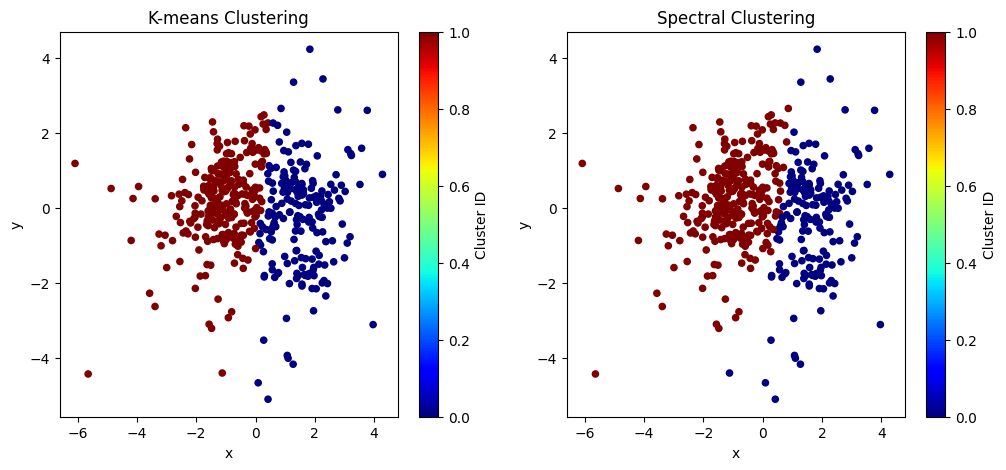

In [17]:
from sklearn import cluster
import pandas as pd

spectral = cluster.SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=0.5)
spectral.fit(points)
labels2 = pd.DataFrame(spectral.labels_,columns=['Cluster ID'])
result2 = pd.concat((points,labels2), axis=1)

fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax1)
ax1.set_title('K-means Clustering')
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax2)
ax2.set_title('Spectral Clustering')

print(pd.crosstab(customers['Channel'], k_means.labels_, rownames=['Channel'], colnames=['K-means']))
print(pd.crosstab(customers['Channel'], spectral.labels_, rownames=['Channel'], colnames=['Spectral']))

## Conclusion

K-means, Hierarchical, DBSCAN, and Spectral Clustering were applied to the Wholesale Customers dataset after preprocessing.

- **K-means (k=2):** 85.9% match with the actual Channel.
- **Spectral Clustering:** Best match at **88.0%**.
- **DBSCAN:** Found 3 clusters but marked **36.4%** as noise.
- **Elbow method:** Supported **k=2**, although cluster separation was not very strong.

**Overall, K-means is preferred because it is simple and easy to interpret.**